### Inference (1D)

Loads a trained 1D run from `out/<run_name>/`, restores checkpoint weights, and runs sampling.

Supports `flow_matching` and `flow_map` checkpoints. Use the project's `.venv` kernel with `scripts/` as the working directory; checkpoints are loaded from `../out/`.

All observed fields in these diagnostics come from the held-out validation split.


In [1]:
from pathlib import Path

import jax
import jax.numpy as jnp
import jax.random as jr
import equinox as eqx
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from einops import rearrange

from joint.config import get_config
from joint.generative import build_model_family
from joint.train import get_optimiser, load_training_state
from joint.utils import ModalitySpec, ModalityInfos, count_parameters


In [2]:
run_name = "0_1d"
out_dir = Path("../out") / run_name
config_path = out_dir / "config.json"
train_state_path = out_dir / "train_state.eqx"

if not config_path.exists():
    raise FileNotFoundError(f"Missing config file: {config_path}")
if not train_state_path.exists():
    raise FileNotFoundError(f"Missing checkpoint file: {train_state_path}")

config = get_config(config_path, reload=True)
key = jr.key(config.seed)

print(f"Loading run '{run_name}' from {out_dir}")


Loading run '0_1d' from ../out/0_1d


In [3]:
# Recreate synthetic 1D dataset exactly as in main_1d.py for comparison plots.
image_shape = (config.data_config.n_channels, config.data_config.n_pix)
backbone_config = config.model_config.backbone
num_patches = config.data_config.n_pix // backbone_config.patch_size
val_fraction = float(getattr(config.data_config, "val_fraction", 0.1))

key_A, key_B = jr.split(key)
A = jr.uniform(key_A, (config.data_config.n_samples,), minval=1.0, maxval=4.0)
B = jr.uniform(key_B, (config.data_config.n_samples,), minval=1.0, maxval=4.0) * -1.0


def grf1d_powerlaw(
    key,
    A: float,
    B: float,
    n: int,
    L: float,
    k0: float = 1.0,
    mean: float = 0.0,
    zero_mode: float = 0.0,
    eps: float = 1e-12,
):
    k = 2.0 * jnp.pi * jnp.fft.rfftfreq(n, d=L / n)
    Pk = A * jnp.power((jnp.maximum(k, eps) / k0), B)

    key_re, key_im = jr.split(key, 2)
    re = jr.normal(key_re, shape=Pk.shape)
    im = jr.normal(key_im, shape=Pk.shape)
    F = (re + 1j * im) * jnp.sqrt(Pk / 2.0)
    F = F.at[0].set(zero_mode + 0.0j)
    if n % 2 == 0:
        F = F.at[-1].set(jnp.real(F[-1]) + 0.0j)

    field = jnp.fft.irfft(F, n=n)
    field = field * jnp.sqrt(n)
    return field + mean


def generator(_key, a, b):
    return grf1d_powerlaw(
        _key,
        n=config.data_config.n_pix,
        L=1.0,
        A=a,
        B=b,
        k0=2.0 * jnp.pi,
    )


keys = jr.split(key, len(A))
X = jax.vmap(generator)(keys, A, B)
X = X[:, jnp.newaxis, :]
X_mean = jnp.mean(X, axis=0)
X_std = jnp.std(X, axis=0)
X = (X - X_mean) / X_std
Y_raw = jnp.stack([A, B], axis=1)
Y_mean = jnp.mean(Y_raw, axis=0, keepdims=True)
Y_std = jnp.std(Y_raw, axis=0, keepdims=True)
Y_std = jnp.where(Y_std > 0.0, Y_std, 1.0)
Y = (Y_raw - Y_mean) / Y_std

n_samples = len(X)
n_valid = max(1, int(n_samples * val_fraction))
n_valid = min(n_valid, n_samples - 1)
n_train = n_samples - n_valid

key, key_split = jr.split(key)
idx = jr.permutation(key_split, n_samples)
train_idx = idx[:n_train]
valid_idx = idx[n_train:]
X_train, Y_train = X[train_idx], Y[train_idx]
X_valid, Y_valid = X[valid_idx], Y[valid_idx]
Y_train_raw, Y_valid_raw = Y_raw[train_idx], Y_raw[valid_idx]
x_plot_vmin, x_plot_vmax = [
    float(v) for v in jnp.percentile(X_valid, jnp.array([1.0, 99.0]))
]

key, key_ref_idx = jr.split(key)
ref_idx = int(jr.randint(key_ref_idx, shape=(), minval=0, maxval=len(X_valid)))
x_ref_valid = X_valid[ref_idx]
a_ref = Y_valid[ref_idx, 0]
b_ref = Y_valid[ref_idx, 1]
a_ref_raw = a_ref * Y_std[0, 0] + Y_mean[0, 0]
b_ref_raw = b_ref * Y_std[0, 1] + Y_mean[0, 1]


In [4]:
# Rebuild model skeleton and load checkpoint.
modality_infos = ModalityInfos(
    {
        "x": ModalitySpec(
            name="x",
            modality_type="image",
            input_shape=image_shape,
            patch_size=backbone_config.patch_size,
            sequence_length=num_patches,
            embedding_dim=backbone_config.embedding_dim,
        ),
        "a": ModalitySpec(
            name="a",
            modality_type="vector",
            input_shape=(1,),
            sequence_length=1,
            embedding_dim=backbone_config.embedding_dim,
        ),
        "b": ModalitySpec(
            name="b",
            modality_type="vector",
            input_shape=(1,),
            sequence_length=1,
            embedding_dim=backbone_config.embedding_dim,
        ),
    }
)

if str(config.model_config.model_family) not in {"flow_matching", "flow_map"}:
    raise ValueError("These notebooks expect a flow_matching or flow_map run.")

key, key_model = jr.split(key)
family = build_model_family(config, modality_infos, key_model)
v = family.model

opt = get_optimiser(v, config.train_config)
opt_state = opt.init(eqx.filter(v, eqx.is_inexact_array))
v, v_ema, _, _, step = load_training_state(
    train_state_path,
    use_ema=bool(config.train_config.use_ema),
    model=v,
    optimiser=opt,
    optimiser_state=opt_state,
)
v_infer = eqx.nn.inference_mode(v_ema if v_ema is not None else v)

print(f"Model parameters: {count_parameters(v_infer):.3E}")
print(f"Loaded train step: {step}")


Model parameters: 1.202E+05
Loaded train step: 144500


#### Power spectrum at fixed parameters

Generate **100 independent fields at the same raw `(A, B)`**, using the loaded model. Run this after the setup/checkpoint cells above. The cell restores physical field units and compares the mean measured power with the input law `P(k) = A (k / 2π)^B` (`L=1`). Shading is ±1 standard error of the mean.

We omit the fixed DC mode and, for even grids, Nyquist, whose power is halved by the current simulator.


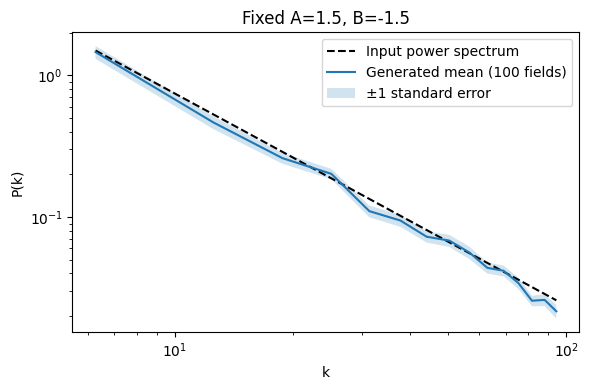

Mean absolute fractional power error: 8.8%


In [5]:
# Fixed raw parameters; change these two numbers to test another setting.
n_power = 100
a_power, b_power = 1.5, -1.5
theta_power = (jnp.array([a_power, b_power]) - Y_mean[0]) / Y_std[0]
noise_key, sample_key = jr.split(jr.fold_in(jr.key(config.seed), 2026))
power_noise = jr.normal(noise_key, (n_power, *image_shape))
power_keys = jr.split(sample_key, n_power)

# Generate only x; keep the same a,b for all 100 independent noise draws.
power_x = jax.lax.map(
    lambda pair: family.sample_modalities_fn(v_infer, {"x": pair[0], "a": theta_power[:1], "b": theta_power[1:]}, ["x"], pair[1],)["x"],
    (power_noise, power_keys), batch_size=10,
)
power_fields = np.asarray(power_x * X_std + X_mean)[:, 0]
assert np.isfinite(power_fields).all()
n = config.data_config.n_pix
# Orthonormal FFT matches the simulator's sqrt(n) scaling; omit DC/Nyquist.
k_power = 2 * np.pi * np.fft.rfftfreq(n, d=1 / n)[1:(n + 1) // 2]
power_each = np.abs(np.fft.rfft(power_fields, norm="ortho")[:, 1:(n + 1) // 2]) ** 2
input_power = a_power * (k_power / (2 * np.pi)) ** b_power

power_mean = power_each.mean(axis=0)
power_sem = power_each.std(axis=0, ddof=1) / np.sqrt(n_power)
fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(k_power, input_power, "k--", label="Input power spectrum")
ax.loglog(k_power, power_mean, label="Generated mean (100 fields)")
ax.fill_between(k_power, power_mean - power_sem, power_mean + power_sem,
                alpha=0.2, label="±1 standard error")
ax.set(xlabel="k", ylabel="P(k)", title=f"Fixed A={a_power:g}, B={b_power:g}")
ax.legend()
fig.tight_layout()
plt.show()
print(f"Mean absolute fractional power error: {np.mean(np.abs(power_mean / input_power - 1)):.1%}")


#### Compare generated to simulated data

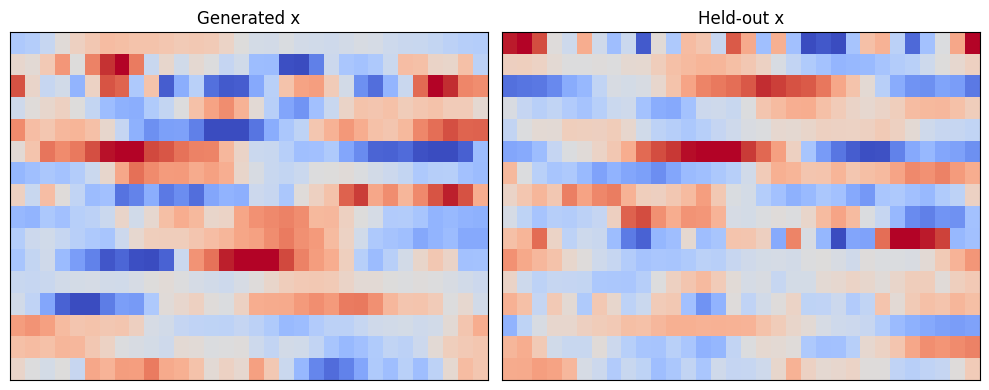

In [6]:
# 1) Unconditional multimodal sampling: generated x vs held-out x.
sample_n_samples = config.sampling_config.n_samples

Z = {
    name: jr.normal(jr.fold_in(key, i), (sample_n_samples ** 2, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}

key, key_sample = jr.split(key)
sample_keys = jr.split(key_sample, sample_n_samples ** 2)
sample_fn = lambda z, sample_key: family.sample_fn(v_infer, z, sample_key)
samples_dict = jax.vmap(sample_fn)(Z, sample_keys)
generated_samples = samples_dict["x"][:, 0, :]

key, key_valid_pick = jr.split(key)
valid_pick = jr.choice(key_valid_pick, len(X_valid), shape=(sample_n_samples ** 2,))
valid_samples = X_valid[valid_pick, 0, :]

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
axs[0].imshow(
    generated_samples,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[0].set_title("Generated x")
axs[1].imshow(
    valid_samples,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[1].set_title("Held-out x")
for ax in axs:
    ax.set_xticks([])
    ax.set_yticks([])
fig.tight_layout()
plt.show()


#### Generated to simulated (fixed physics parameters)

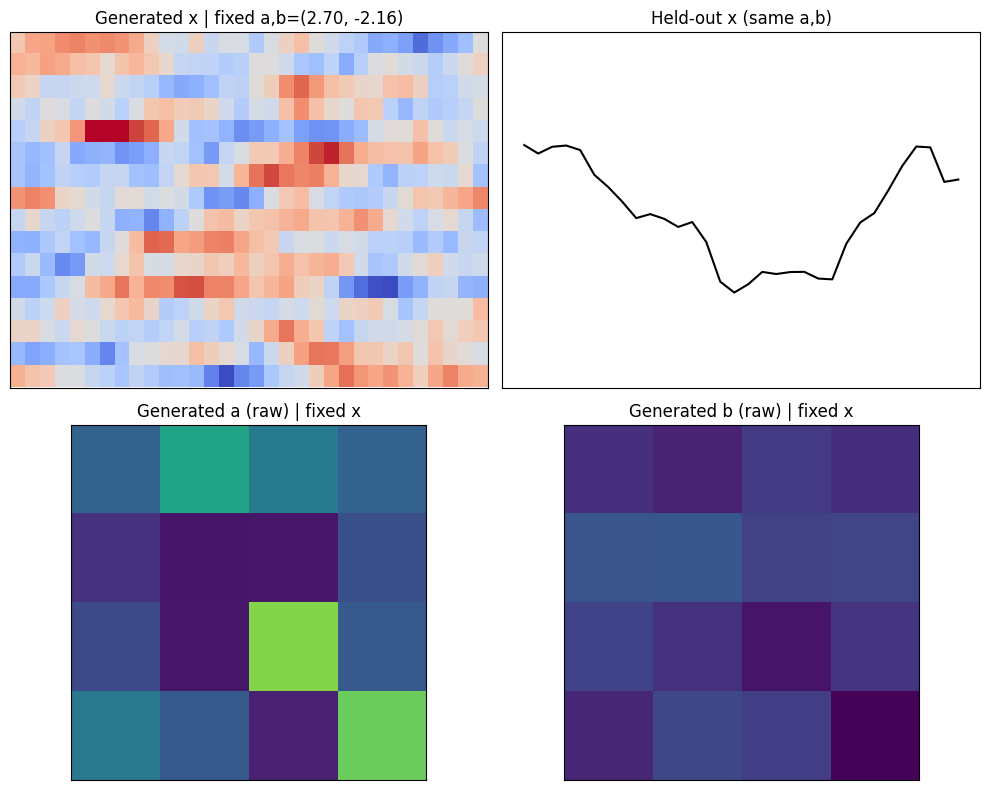

In [7]:
# 2) Conditional tests (same as main_1d.py):
#    - sample x with fixed a,b
#    - sample a,b with fixed x

Z_fixed_ab = {
    name: jr.normal(jr.fold_in(key, i), (sample_n_samples ** 2, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}
Z_fixed_ab["a"] = jnp.full((sample_n_samples ** 2, 1), a_ref)
Z_fixed_ab["b"] = jnp.full((sample_n_samples ** 2, 1), b_ref)

key, key_cond_ab = jr.split(key)
cond_keys_ab = jr.split(key_cond_ab, sample_n_samples ** 2)
sample_fn_fixed_ab = lambda z, sample_key: family.sample_modalities_fn(v_infer, z, ["x"], sample_key)
samples_fixed_ab = jax.vmap(sample_fn_fixed_ab)(Z_fixed_ab, cond_keys_ab)
generated_x_fixed_ab = samples_fixed_ab["x"][:, 0, :]

x_fixed = X_valid[:1]
Z_fixed_x = {
    name: jr.normal(jr.fold_in(key, i + 100), (sample_n_samples ** 2, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}
Z_fixed_x["x"] = jnp.repeat(x_fixed, sample_n_samples ** 2, axis=0)

key, key_cond_x = jr.split(key)
cond_keys_x = jr.split(key_cond_x, sample_n_samples ** 2)
sample_fn_fixed_x = lambda z, sample_key: family.sample_modalities_fn(v_infer, z, ["a", "b"], sample_key)
samples_fixed_x = jax.vmap(sample_fn_fixed_x)(Z_fixed_x, cond_keys_x)
generated_a_grid = rearrange(samples_fixed_x["a"], "(p q) 1 -> p q", p=sample_n_samples)
generated_b_grid = rearrange(samples_fixed_x["b"], "(p q) 1 -> p q", p=sample_n_samples)

fig, axs = plt.subplots(2, 2, figsize=(10, 8))
axs[0, 0].imshow(
    generated_x_fixed_ab,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[0, 0].set_title(f"Generated x | fixed a,b=({float(a_ref_raw):.2f}, {float(b_ref_raw):.2f})")
axs[0, 1].plot(x_ref_valid[0], color="black", linewidth=1.5)
# axs[0, 1].plot(generated_x_fixed_ab, linewidth=1.5, color="royalblue")
axs[0, 1].set_ylim(float(X_valid.min()), float(X_valid.max()))
axs[0, 1].set_title("Held-out x (same a,b)")

generated_a_grid_raw = generated_a_grid * Y_std[0, 0] + Y_mean[0, 0]
generated_b_grid_raw = generated_b_grid * Y_std[0, 1] + Y_mean[0, 1]
axs[1, 0].imshow(generated_a_grid_raw, cmap="viridis", vmin=Y_valid_raw[:, 0].min(), vmax=Y_valid_raw[:, 0].max())
axs[1, 0].set_title("Generated a (raw) | fixed x")
axs[1, 1].imshow(generated_b_grid_raw, cmap="viridis", vmin=Y_valid_raw[:, 1].min(), vmax=Y_valid_raw[:, 1].max())
axs[1, 1].set_title("Generated b (raw) | fixed x")

for row in axs:
    for ax in row:
        ax.set_xticks([])
        ax.set_yticks([])
fig.tight_layout()
plt.show()


#### Posterior sampling for posterior predictive

Given observed conditioning data $x_{\mathrm{obs}}$, the posterior predictive for a new realization $x_{\mathrm{new}}$ is
$$
p(x_{\mathrm{new}} \mid x_{\mathrm{obs}})
= \int p(x_{\mathrm{new}} \mid a,b)\, p(a,b \mid x_{\mathrm{obs}})\, \text{d}a\, \text{d}b.
$$

A Monte Carlo estimator with $S$ samples is:

1. Draw $\theta^{(s)}=(a^{(s)}, b^{(s)}) \sim p(a,b \mid x_{\mathrm{obs}})$ for $s=1,\dots,S$.
2. Draw $x_{\mathrm{new}}^{(s)} \sim p(x \mid \theta^{(s)})$.

Then
$$
p(x_{\mathrm{new}} \mid x_{\mathrm{obs}})
\approx \frac{1}{S} \sum_{s=1}^S \delta\!\left(x_{\mathrm{new}} - x_{\mathrm{new}}^{(s)}\right),
$$
and for any summary/statistic $f$,
$$
\mathbb{E}[f(x_{\mathrm{new}}) \mid x_{\mathrm{obs}}]
\approx \frac{1}{S} \sum_{s=1}^S f\!\left(x_{\mathrm{new}}^{(s)}\right).
$$


In [8]:
# 3) Sample many (a, b) given a randomly selected held-out x.

import time

n_ab_samples = 10_000

key_random = jr.key(int(time.time()))

key, key_rand_x, key_noise = jr.split(key_random, 3)
rand_x_idx = int(jr.randint(key_rand_x, shape=(), minval=0, maxval=len(X_valid)))
x_anchor = X_valid[rand_x_idx : rand_x_idx + 1]
a_true_norm = float(Y_valid[rand_x_idx, 0])
b_true_norm = float(Y_valid[rand_x_idx, 1])
a_true = float(Y_valid_raw[rand_x_idx, 0])
b_true = float(Y_valid_raw[rand_x_idx, 1])

Z_many_ab = {
    name: jr.normal(jr.fold_in(key_noise, i + 200), (n_ab_samples, *spec.input_shape))
    for i, (name, spec) in enumerate(modality_infos.items())
}
Z_many_ab["x"] = jnp.repeat(x_anchor, n_ab_samples, axis=0)

key, key_cond_many = jr.split(key)
cond_keys_many = jr.split(key_cond_many, n_ab_samples)
sample_fn_many_ab = lambda z, sample_key: family.sample_modalities_fn(v_infer, z, ["a", "b"], sample_key)

samples_many_ab = jax.vmap(sample_fn_many_ab)(Z_many_ab, cond_keys_many)
a_samples_norm = samples_many_ab["a"][:, 0]
b_samples_norm = samples_many_ab["b"][:, 0]
a_samples = a_samples_norm * Y_std[0, 0] + Y_mean[0, 0]
b_samples = b_samples_norm * Y_std[0, 1] + Y_mean[0, 1]


#### Analytic posterior baseline

For this periodic Gaussian simulator, the independent modes
$z_q=\mathrm{rFFT}(x_{\rm physical})/\sqrt{n}$ have power $P_q=Aq^B$.
With the training priors $A\sim U(1,4)$ and $B\sim U(-4,-1)$,

$$\log p(A,B\mid x)=C-\sum_{q>0}\left[w_q\log P_q+\frac{|z_q|^2}{P_q}\right]$$

inside that prior rectangle, and zero posterior density outside it. Here $w_q=1$
for complex modes and $w_q=1/2$ for the even-grid Nyquist mode, whose real variance
is $P_q/2$ in the current simulator. The fixed DC mode carries no parameter information.

The likelihood is analytic; posterior normalization and 68%/95% HPD contours are
computed on a uniform grid over the full prior. Both contours use the same
`x_anchor`. Run the preceding posterior-sampling cell first. Model samples outside
the prior are retained in the learned contours and reported below.


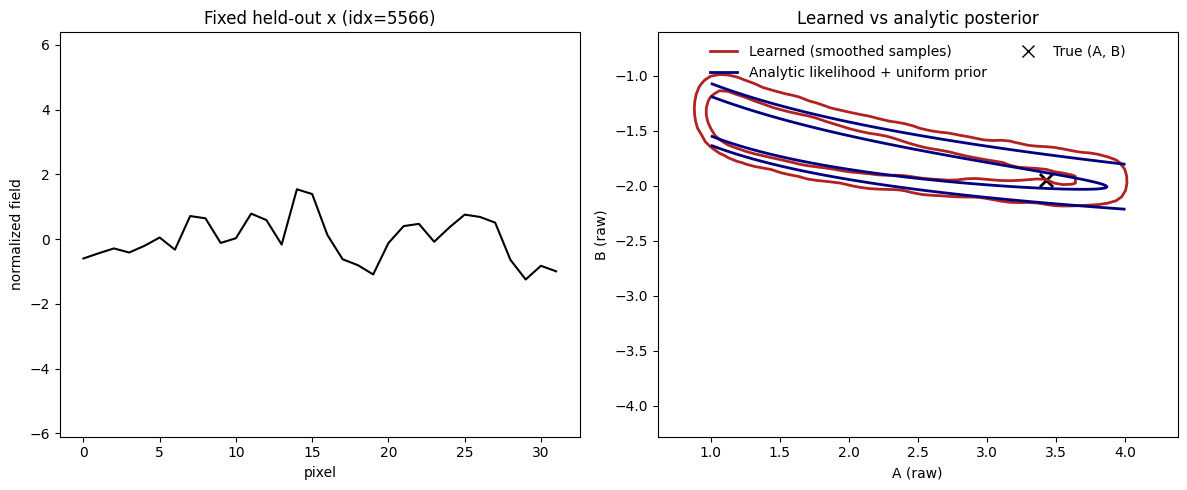

Learned samples outside the training prior: 0.5%


In [ ]:
# Compare the learned samples with the exact simulator posterior for the same x.
a_np, b_np = np.asarray(a_samples), np.asarray(b_samples)
assert np.isfinite(a_np).all() and np.isfinite(b_np).all()

# Keep all model samples, including any outside the prior; pad for smoothing.
plot_bounds = []
for values, prior in ((a_np, (1, 4)), (b_np, (-4, -1))):
    lo, hi = min(values.min(), prior[0]), max(values.max(), prior[1])
    padding = 0.1 * (hi - lo)
    plot_bounds.append((lo - padding, hi + padding))
hist, x_edges, y_edges = np.histogram2d(a_np, b_np, bins=60, range=plot_bounds)


def smooth_hist2d(hist, sigma=1.2):
    radius = max(1, int(round(3 * sigma)))
    offsets = np.arange(-radius, radius + 1)
    kernel = np.exp(-0.5 * (offsets / sigma) ** 2)
    kernel /= kernel.sum()
    for axis in (0, 1):
        hist = np.apply_along_axis(lambda row: np.convolve(row, kernel, mode="same"), axis, hist)
    return hist / hist.sum()


def hpd_levels(probability):
    ordered = np.sort(probability.ravel())[::-1]
    cumulative = np.cumsum(ordered) / ordered.sum()
    indices = np.searchsorted(cumulative, [0.95, 0.68])
    return np.unique(ordered[np.minimum(indices, len(ordered) - 1)])


prob = smooth_hist2d(hist)
x_centers = 0.5 * (x_edges[:-1] + x_edges[1:])
y_centers = 0.5 * (y_edges[:-1] + y_edges[1:])

# Undo pixelwise normalization and recover the independent Fourier modes.
x_physical = np.asarray(x_anchor[0, 0] * X_std[0] + X_mean[0])
fourier = np.fft.rfft(x_physical, norm="ortho")[1:]  # DC is fixed, so omit it.
q = np.arange(1, len(fourier) + 1)  # k/k0 for L=1 and k0=2*pi.
weights = np.ones(len(q))
if len(x_physical) % 2 == 0:
    weights[-1] = 0.5  # Nyquist is real, with variance P/2 in this simulator.

# Exact log likelihood, evaluated over the FULL uniform-prior rectangle.
a_grid = np.linspace(1.0, 4.0, 301)
b_grid = np.linspace(-4.0, -1.0, 301)
scaled_power = (np.abs(fourier)[None, :] ** 2 * q[None, :] ** (-b_grid[:, None])).sum(axis=1)
log_posterior = (-weights.sum() * np.log(a_grid)[None, :]
                 - b_grid[:, None] * np.sum(weights * np.log(q))
                 - scaled_power[:, None] / a_grid[None, :])
analytic_prob = np.exp(log_posterior - log_posterior.max())
analytic_prob /= analytic_prob.sum()

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].plot(np.asarray(x_anchor[0, 0]), color="black", linewidth=1.5)
axs[0].set(title=f"Fixed held-out x (idx={rand_x_idx})", xlabel="pixel", ylabel="normalized field",
           ylim=(float(X_valid.min()), float(X_valid.max())))
axs[1].contour(x_centers, y_centers, prob.T, levels=hpd_levels(prob),
               colors="firebrick", linestyles=["-", "-"], linewidths=2)
axs[1].contour(a_grid, b_grid, analytic_prob, levels=hpd_levels(analytic_prob),
               colors="navy", linestyles=["-", "-"], linewidths=2)
axs[1].scatter([a_true], [b_true], c="black", marker="x", s=90, linewidths=2)
axs[1].set(xlabel="A (raw)", ylabel="B (raw)", title="Learned vs analytic posterior")
axs[1].legend(handles=[
    Line2D([], [], color="firebrick", lw=2, label="Learned (smoothed samples)"),
    Line2D([], [], color="navy", lw=2, label="Analytic likelihood + uniform prior"),
    # Line2D([], [], color="gray", lw=2, linestyle="-", label="68% HPD"),
    # Line2D([], [], color="gray", lw=2, linestyle="--", label="95% HPD"),
    Line2D([], [], color="black", marker="x", linestyle="None", markersize=8, label="True (A, B)"),
], loc="upper center", ncol=2, frameon=False,)# bbox_to_anchor=(0.5, -0.2),)
fig.tight_layout()
plt.show()
outside_prior = (a_np < 1) | (a_np > 4) | (b_np < -4) | (b_np > -1)
print(f"Learned samples outside the training prior: {outside_prior.mean():.1%}")


In [9]:
a_samples.shape

(10000,)

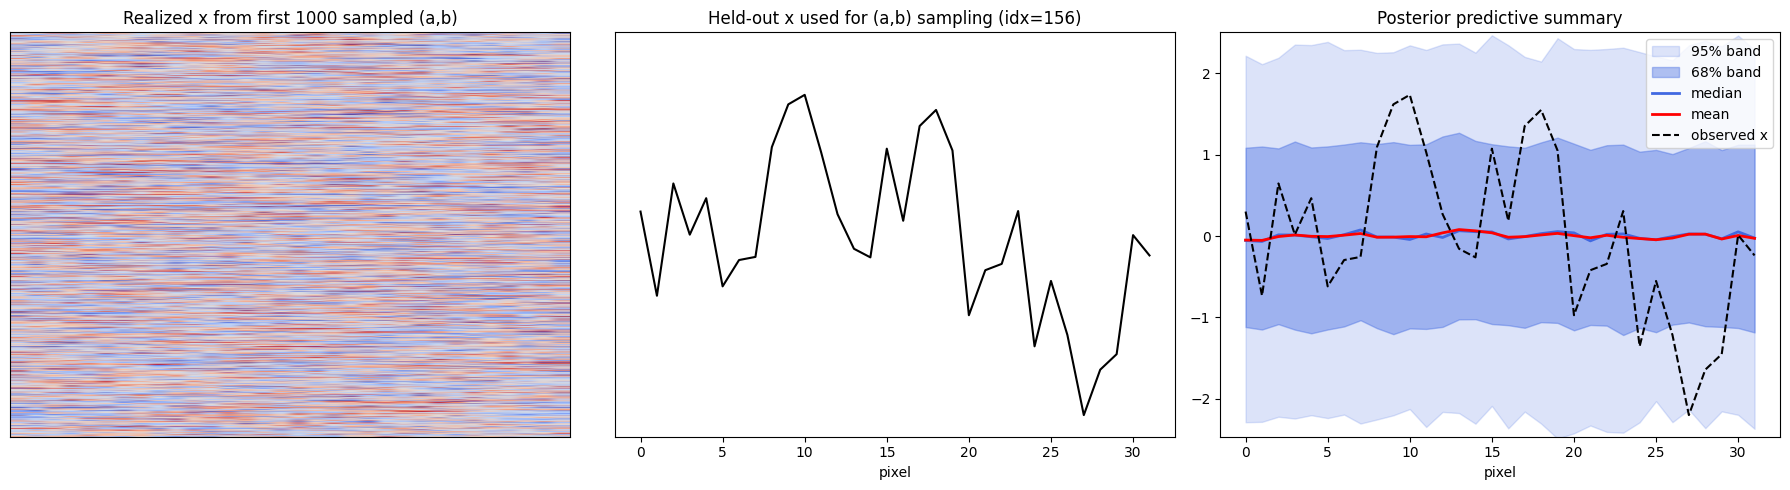

In [10]:
# 4) From sampled (a,b), generate real x realizations for first N**2 and summarize posterior predictive uncertainty.
N = sample_n_samples
n_panel = 1_000 # N ** 2
if len(a_samples) < n_panel:
    raise ValueError(f"Need at least {n_panel} sampled pairs, got {len(a_samples)}")

a_panel = a_samples[:n_panel]
b_panel = b_samples[:n_panel]

key, key_real_panel = jr.split(key)
real_keys = jr.split(key_real_panel, n_panel)

# Sample real fields from the simulator using sampled parameter pairs.
x_real_panel = jax.vmap(generator)(real_keys, a_panel, b_panel)
x_real_panel = x_real_panel[:, jnp.newaxis, :]
x_real_panel = (x_real_panel - X_mean) / X_std

x_real_grid = np.asarray(x_real_panel[:, 0, :])
x_anchor_1d = np.asarray(x_anchor[0, 0])

# Posterior predictive summary bands at each pixel.
x_med = np.percentile(x_real_grid, 50.0, axis=0)
x_mean = np.mean(x_real_grid, axis=0)
x_lo68 = np.percentile(x_real_grid, 16.0, axis=0)
x_hi68 = np.percentile(x_real_grid, 84.0, axis=0)
x_lo95 = np.percentile(x_real_grid, 2.5, axis=0)
x_hi95 = np.percentile(x_real_grid, 97.5, axis=0)
pixels = np.arange(x_real_grid.shape[1])

fig, axs = plt.subplots(1, 3, figsize=(18, 5))
axs[0].imshow(
    x_real_grid,
    cmap="coolwarm",
    vmin=x_plot_vmin,
    vmax=x_plot_vmax,
    aspect="auto",
)
axs[0].set_title(f"Realized x from first {n_panel} sampled (a,b)")
axs[0].set_xticks([])
axs[0].set_yticks([])

axs[1].plot(x_anchor_1d, color="black", linewidth=1.5)
axs[1].set_title(f"Held-out x used for (a,b) sampling (idx={rand_x_idx})")
axs[1].set_xlabel("pixel")
axs[1].set_ylim(x_plot_vmin, x_plot_vmax)
axs[1].set_yticks([])

axs[2].fill_between(pixels, x_lo95, x_hi95, color="royalblue", alpha=0.18, label="95% band")
axs[2].fill_between(pixels, x_lo68, x_hi68, color="royalblue", alpha=0.4, label="68% band")
axs[2].plot(pixels, x_med, color="royalblue", linewidth=2.0, label="median")
axs[2].plot(pixels, x_mean, color="red", linewidth=2.0, label="mean")
axs[2].plot(pixels, x_anchor_1d, color="black", linestyle="--", linewidth=1.5, label="observed x")
axs[2].set_title("Posterior predictive summary")
axs[2].set_xlabel("pixel")
axs[2].set_ylim(x_plot_vmin, x_plot_vmax)
axs[2].legend(loc="best")

fig.tight_layout()
plt.show()
